In [1]:
!pip install --upgrade binance-historical-data plotly -q
!pip install ta pandas_ta

In [2]:
import os
import ta
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from itertools import product
from sklearn.cluster import KMeans
from ta.trend import PSARIndicator
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency= data_frequency,
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data

In [3]:
ticker = 'BTCUSDT'
data_frequency = '15m'
download_ticker(ticker, "2024-01-01", "2025-08-01", data_frequency)
df = process_csv_files(ticker, data_frequency)
df = df.drop(columns=['High','Low','close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
df.set_index('open_time', inplace=True)
rsi = ta.momentum.RSIIndicator(df['Close'], window=14)
df['RSI'] = rsi.rsi()
df

---> Found overall tickers: 3221
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 15m
---> Start Date: 20240101
---> End Date: 20250801


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For CUSDT new data saved for: 0 months 0 days


,Open,Close,volume,RSI
open_time,,,,
2024-01-01 00:15:00,42488.00,42419.73,392.24889,NaN
2024-01-01 00:30:00,42419.73,42441.32,319.90644,NaN
2024-01-01 00:45:00,42441.32,42475.23,127.81493,NaN
2024-01-01 01:00:00,42475.23,42466.33,188.76099,NaN
2024-01-01 01:15:00,42466.32,42493.16,152.48691,NaN
...,...,...,...,...
2025-08-01 22:45:00,113066.00,113141.05,407.93369,33.517152
2025-08-01 23:00:00,113141.05,113311.32,184.37083,37.845875
2025-08-01 23:15:00,113311.32,113549.44,100.52142,43.396430


In [4]:
def calculate_macd(df, short_window=70, long_window=102, price_col='Close'):
  # Calculate Simple Moving Average of 2 periods
  df['MA_s'] = df[price_col].rolling(window=short_window).mean()
  df['MA_l'] = df[price_col].rolling(window=long_window).mean()

  # Calculate MACD, signal, and histogram lines
  df['MACD'] = df['MA_s'] - df['MA_l']
  df['MACD_sign'] = df['MACD'].rolling(window = 9).mean()
  df['MACD_his'] = df['MACD'] - df['MACD_sign']

  return df

#Calculate the slope of 2 MAs
# df['MA_short_slope'] = df['MA_short'].diff()
# df['MA_long_slope'] = df['MA_long'].diff()
# df['MA_long_short_diff'] = df['MA_short_slope'] - df['MA_long_slope']

#Calculate the mean volume
df['Vol_mean'] = df['volume'].rolling(window=10).mean()

df = calculate_macd(df).round(4)
df.head(200)

,Open,Close,volume,RSI,Vol_mean,MA_s,MA_l,MACD,MACD_sign,MACD_his
open_time,,,,,,,,,,
2024-01-01 00:15:00,42488.00,42419.73,392.2489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:30:00,42419.73,42441.32,319.9064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 00:45:00,42441.32,42475.23,127.8149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 01:00:00,42475.23,42466.33,188.7610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 01:15:00,42466.32,42493.16,152.4869,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2024-01-03 01:00:00,45135.61,45182.16,284.1824,55.9627,311.3353,45262.1499,45221.3252,40.8247,109.0259,-68.2012
2024-01-03 01:15:00,45182.16,45162.30,228.4213,55.0364,300.3150,45257.9609,45230.9600,27.0009,92.0245,-65.0236
2024-01-03 01:30:00,45162.31,45241.50,242.9004,58.0206,298.9317,45252.1769,45236.9542,15.2226,75.5196,-60.2970


In [5]:
def generate_positions(df, rsi = 'RSI', vol= 'volume', vol_mean = 'Vol_mean', macd = 'MACD', macd_his = 'MACD_his'):
# Calculate signal_position
    pos = []
    rsi_pos = np.where((df[rsi].rolling(window=10).min()) < 60, 1, np.where((df[rsi].rolling(window=10).max()) > 40, -1, 0))
    his_pos = np.sign(df[macd_his]).replace(0, np.nan)
    macd_pos = np.sign(df[macd]).replace(0, np.nan)
    vol_pos = np.where(df[vol] > df[vol_mean].shift(1), 1, 0)
# Generate overall position
    pos = np.where(
        (his_pos == 1) &
         ((macd_pos == 1) | (vol_pos == 1) | (rsi_pos == 1)),
        1,
        np.where(
        (his_pos == -1) &
         ((macd_pos == -1) | (vol_pos == 1) | (rsi_pos == -1)),
        -1,
        0))

#Refill sustained trend:
    for i in range(2, len(df)):
        if pos [i] == 0 and pos[i-1] == pos [i-2]:
            pos[i] = pos[i-1]

# # Carry forward last position when POS == 0
#     pos = pd.Series(pos, index=df.index).replace(0, np.nan).ffill().fillna(0).astype(int)

    return pos

df['POS'] = generate_positions(df)
df.head (200)

,Open,Close,volume,RSI,Vol_mean,MA_s,MA_l,MACD,MACD_sign,MACD_his,POS
open_time,,,,,,,,,,,
2024-01-01 00:15:00,42488.00,42419.73,392.2489,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2024-01-01 00:30:00,42419.73,42441.32,319.9064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2024-01-01 00:45:00,42441.32,42475.23,127.8149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2024-01-01 01:00:00,42475.23,42466.33,188.7610,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2024-01-01 01:15:00,42466.32,42493.16,152.4869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...
2024-01-03 01:00:00,45135.61,45182.16,284.1824,55.9627,311.3353,45262.1499,45221.3252,40.8247,109.0259,-68.2012,-1
2024-01-03 01:15:00,45182.16,45162.30,228.4213,55.0364,300.3150,45257.9609,45230.9600,27.0009,92.0245,-65.0236,-1
2024-01-03 01:30:00,45162.31,45241.50,242.9004,58.0206,298.9317,45252.1769,45236.9542,15.2226,75.5196,-60.2970,-1


# Logic:

*   MACD_histogram (Main):
    *   1 when positive
    *   -1 when negative

*   RSI:
    *   1 when the min value within 5 window is less than 30
    *   -1 when the max value within 5 window is more than 70
    
*   MACD:
    *   1 when positive
    *   -1 when negative

*   Volume:
    *   1 when vol > vol_mean.shift(1)
    *   0 when vol < vol_mean.shift(1)

Long when the main factor = 1, one in three sub factors meet requirements.
Short when the main factor = -1, one in three sub factors meet requirements

In [13]:
def calculate_daily_pnls (close = df["Close"], open = df["Open"], pos = df['POS']):
  long_pnl = (close - open)/open
  short_pnl = (open - close)/open
  pnls = np.where(pos.shift(1) == 1, long_pnl, np.where(pos.shift(1) == -1, short_pnl, 0))
  return pnls

def realised_pnls (pnls, pos):
  fee = 0.0005
  # Create boolean conditions for np.select
  # cond_no_trade = (pos[0])
  cond_same_pos = (pos.shift(1) == pos.shift(2)) # Position held for at least 2 periods
  cond_diff_pos = (pos.shift(1) != pos.shift(2)) # Position changed

  # Apply np.select with conditions having the same shape
  # realised_pnls = np.select(
  #     [cond_same_pos, cond_diff_pos],
  #     [pnls, pnls - fee],
  #     default = 0 # Handle the first two rows (NaNs from shifting) by setting pnl to 0
  # )
  realised_pnls = np.where(pnls == 0, pnls,
                           np.select((cond_same_pos, cond_diff_pos),
                                     (pnls, pnls - fee)))
  return realised_pnls

df['Pnls'] = calculate_daily_pnls()
df['Realised_Pnls'] = realised_pnls(df['Pnls'], df['POS'])

# df["Pnls"] = df["Pnls"].fillna(0)

# Cumulative Returns
df["Cumulative_Returns"] = (1 + df["Realised_Pnls"]).cumprod()

df = df.round(4)
# df.sort_values(by='Cumulative_Returns', ascending=False).head(100)
df.head(200)

,Open,Close,volume,RSI,Vol_mean,MA_s,MA_l,MACD,MACD_sign,MACD_his,POS,Pnls,Realised_Pnls,Cumulative_Returns
open_time,,,,,,,,,,,,,,
2024-01-01 00:15:00,42488.00,42419.73,392.2489,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0000,0.0000,1.0000
2024-01-01 00:30:00,42419.73,42441.32,319.9064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0000,0.0000,1.0000
2024-01-01 00:45:00,42441.32,42475.23,127.8149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0000,0.0000,1.0000
2024-01-01 01:00:00,42475.23,42466.33,188.7610,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0000,0.0000,1.0000
2024-01-01 01:15:00,42466.32,42493.16,152.4869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0000,0.0000,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-01-03 01:00:00,45135.61,45182.16,284.1824,55.9627,311.3353,45262.1499,45221.3252,40.8247,109.0259,-68.2012,-1,-0.0010,-0.0010,1.0137
2024-01-03 01:15:00,45182.16,45162.30,228.4213,55.0364,300.3150,45257.9609,45230.9600,27.0009,92.0245,-65.0236,-1,0.0004,0.0004,1.0141
2024-01-03 01:30:00,45162.31,45241.50,242.9004,58.0206,298.9317,45252.1769,45236.9542,15.2226,75.5196,-60.2970,-1,-0.0018,-0.0018,1.0123


In [14]:
def get_periods_per_year(frequency=str):
    if frequency.endswith('m'):  # phút
        minutes = int(frequency[:-1])
        return int(365 * 24 * 60 / minutes)
    elif frequency.endswith('h'):  # giờ
        hours = int(frequency[:-1])
        return int(365 * 24 / hours)
    elif frequency.endswith('d'):  # ngày
        return 365
    elif frequency.endswith('w'):  # tuần
        return 52
    else:
        raise ValueError(f"Không hỗ trợ định dạng data_frequency: {frequency}")

def annualised_sharpe_ratio(pnls,data_frequency):
  periods_per_year = get_periods_per_year(data_frequency)
  sharpe = np.sqrt(periods_per_year) * pnls.mean() / pnls.std()
  return sharpe

def max_drawdown(pnls):
  # pnls = np.asarray(pnls)
  # running_max = np.maximum.accumulate(1+pnls)
  # drawdowns = (pnls - running_max)/running_max
  # return drawdowns.min()
  """Tính toán Maximum Drawdown từ một chuỗi lợi nhuận."""
  equity_curve = (1 + pnls).cumprod()
  peak = equity_curve.expanding(min_periods=1).max()
  drawdown = (equity_curve - peak) / peak
  return drawdown.min()

def total_return(pnls): # Unit: %
  total_return = (pnls + 1).prod() - 1
  return total_return

def backtest(df, short, long):
  df_copy = df.copy()
  df_copy = calculate_macd(df_copy, short_window=short, long_window=long, price_col='Close').round(4)
  df_copy['POS'] = generate_positions(df_copy)
  df_copy['Pnls'] = calculate_daily_pnls(df_copy["Close"], df_copy["Open"], df_copy['POS'])
  df_copy['Realised_Pnls'] = realised_pnls(df_copy['Pnls'], df_copy['POS'])

  sharpe = annualised_sharpe_ratio(df_copy["Realised_Pnls"], data_frequency)
  max_dd = max_drawdown(df_copy["Realised_Pnls"])
  returns = total_return(df_copy["Realised_Pnls"])
  return sharpe, max_dd, returns


In [ ]:
max_dd = max_drawdown(df["Realised_Pnls"])
max_dd
# total_return(df["Pnls"])

In [15]:
short_range = range (5,106,5)
long_range = range (10,171, 8)
sweep_test_results = []

for short in short_range:
  for long in long_range:
    if short<long:
      sharpe, max_dd, returns = backtest(df, short, long)
      sweep_test_results.append ({'short_window': short, 'long_window': long,
                                  'sharpe_ratio': sharpe, 'final_returns': returns, 'max_drawdown': max_dd})

sweep_test = pd.DataFrame(sweep_test_results)
sweep_test

,short_window,long_window,sharpe_ratio,final_returns,max_drawdown
0,5,10,-4.717816,-0.981502,-0.982799
1,5,18,-3.890101,-0.963590,-0.964681
2,5,26,-4.005794,-0.966557,-0.967612
3,5,34,-4.365511,-0.974899,-0.976414
4,5,42,-3.666406,-0.956137,-0.959589
...,...,...,...,...,...
306,105,138,-2.322133,-0.872474,-0.894687
307,105,146,-2.155946,-0.854668,-0.875227
308,105,154,-1.914884,-0.823399,-0.851499
309,105,162,-2.230562,-0.862892,-0.882422


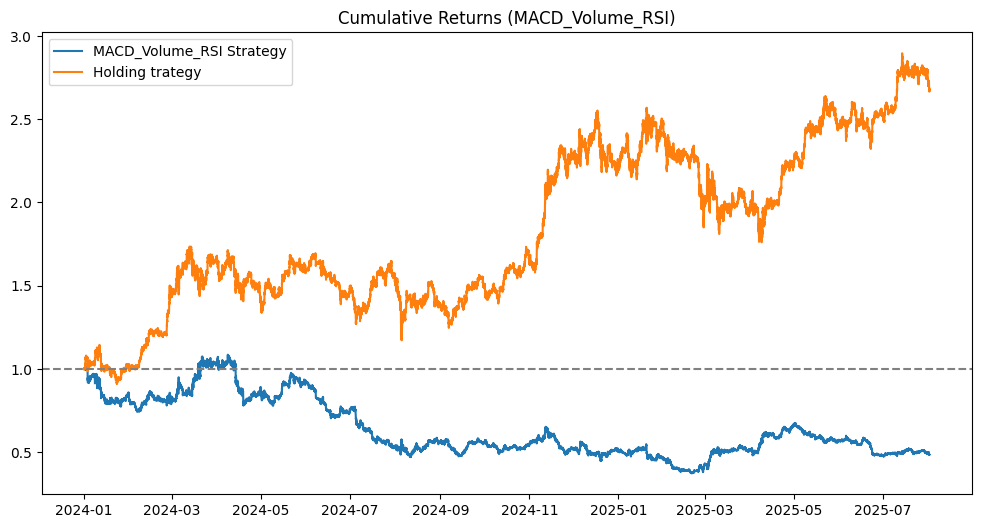

In [16]:
plt.figure(figsize=(12,6))
plt.plot(df.index, df['Cumulative_Returns'], label="MACD_Volume_RSI Strategy")
holding_returns = (df['Close'].pct_change()+1).cumprod()
plt.plot(df.index, holding_returns, label="Holding trategy")
plt.axhline(1, color="gray", linestyle="--")  # baseline
plt.legend()
plt.title("Cumulative Returns (MACD_Volume_RSI)")
plt.show()